# MCDI505 — Análisis de Series de Tiempo

## Sumativa 2 — Modelos clásicos (ARIMA / SARIMA) aplicados al consumo eléctrico comercial depurado

| **Antecedente** | **Información** |
|:---|:---|
| **Estudiante** | Claudio Rodolfo Alarcón Pradenas |
| **Programa** | Magíster en Ciencia de Datos e Inteligencia Artificial — Universidad Andrés Bello |
| **Docente** | Dr. Harvey Jezlid Rosas Quintero |
| **Asignatura** | MCDI505 — Análisis de Series de Tiempo |
| **Evaluación** | Sumativa 2 · Semana 2 · Fase 2 
| **Dataset** | `consumo_electrico_litoral_depurado.csv` |
| **Repositorio** | `https://github.com/claudioalarconP/Analisis_de_serie_de_tiempo` |

## Hoja de decisiones

| Criterio | Decisión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Estacionariedad y transformaciones | Logaritmo; d = 1, D = 1, s = 12 | En log: ADF p = 0,155 y KPSS p ≥ 0,10 (no concluyente). Con ∇∇₁₂: ADF p < 0,001, KPSS p ≥ 0,10 y varianza −70 % (Tabla 1, Fig. 2) | Solo ∇₁₂ (ADF p = 0,101; ρ1 = 0,849); d = 2 (varianza +90 %; ρ1 = −0,425); escala original (Box-Cox λ = 0,004, IC 95 % [−1,45; 1,49]) | Log adoptado por interpretabilidad relativa, no por necesidad demostrada; pronósticos retransformados a GWh con corrección de sesgo |
| 2. Identificación y estimación | Desde ACF/PACF: M1 (0,1,0)(0,1,1)₁₂, M2 (0,1,1)(0,1,1)₁₂, M3 (1,1,0)(0,1,1)₁₂, M4 (0,1,0)(1,1,0)₁₂. Con intervención: M5 = M2 + `covid`; M6 = M2 + `covid` + `agudo` | ACF de w_t solo en 12 (−0,298); PACF en 12 y 24; sin el shock aparece ρ1 = −0,256. En M6, θ1 = −0,462 (p LR < 0,001) (Tabla 2, Fig. 3) | MA regular sin intervención (M2: p = 0,689) o solo con `covid` (M5: p = 0,159); D = 0 con indicadoras mensuales (Ljung-Box K = 24, p = 0,001) | Θ1 entre −0,969 y −0,982: p-valores indicativos; `agudo` es retrospectiva y sus coeficientes son descriptivos, no causales |
| 3. Selección y comparación | M6 como modelo de análisis (decisión de compromiso); M4 como alternativa predictiva | M6: AIC = −331,36 y BIC = −319,26 (mínimos); RMSE = 5,71 y MAE = 5,20 GWh. M4: RMSE = 4,12 y MAE = 3,71 (mínimos); ΔAIC = 53,55. Naive estacional: 7,26 y 6,53 (Tabla 3, Fig. 4) | M4 como modelo final de análisis (se conserva como alternativa predictiva): logra el menor error en 2023, aunque desde un único origen de validación; con las intervenciones de M6 su RMSE sube a 7,79, por lo que estas no son compatibles con esa especificación | Ningún modelo domina en todos los criterios; M6 subestima los 12 meses de 2023 (ME = +5,20 GWh) y la decisión debe confirmarse con validación de origen móvil |
| 4. Diagnóstico de residuos | Pruebas mínimas sobre M6; M4 y M2 como contraste | Ljung-Box K = 12: p = 0,340; K = 24: p = 0,040; Jarque-Bera p = 0,227; ARCH-LM p = 0,825 (Tabla 4, Fig. 5) | Ampliar M6 (AIC mayor; Ljung-Box K = 24 con p ≤ 0,038) | Normalidad y ARCH no se rechazan; la autocorrelación remanente a 24 rezagos queda como limitación de M6 |

## 0. Configuración y datos

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, het_goldfeldquandt
from statsmodels.tools.sm_exceptions import ConvergenceWarning

from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=DeprecationWarning)   # avisos internos de NumPy/statsmodels, sin efecto numérico
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning) # p de KPSS fuera de tabla: se marca como "≥ 0,100" en la Tabla 1
# Los avisos de convergencia NO se silencian: se registran en la Tabla 2 y cualquier otro aviso queda visible en la salida.
SEMILLA = 505
np.random.seed(SEMILLA)
S = 12                                     # periodo estacional mensual
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.titlesize": 11, "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False})
ROJO, AZUL, GRIS, VERDE, NARANJA, MORADO = "#b30338", "#0057b8", "#9e9e9e", "#2e7d32", "#ef6c00", "#6a1b9a"
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)

# --- Localización del CSV con rutas relativas (junto al notebook o en data/, data/raw, data/processed) ---
ARCHIVO = "consumo_electrico_litoral_depurado.csv"
rutas = [Path(*[".."] * n) / sub / ARCHIVO for n in range(4) for sub in (".", "data", "data/raw", "data/processed")]
ruta = next((r for r in rutas if r.exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró {ARCHIVO}: ubíquelo junto al notebook o en data/, data/raw o data/processed.")

df = pd.read_csv(ruta, parse_dates=["fecha"], index_col="fecha")
assert df.index.is_monotonic_increasing and not df.index.duplicated().any(), "índice desordenado o con duplicados"
assert pd.date_range(df.index.min(), df.index.max(), freq="MS").difference(df.index).empty, "faltan meses"
df.index.freq = "MS"
y = df["consumo_gwh"]
assert y.notna().all(), "la serie depurada no debe tener faltantes"
assert (y > 0).all(), "el logaritmo exige valores estrictamente positivos"

# Partición oficial: 2024 no se utiliza esta semana
y_train = y["2015-01":"2022-12"]
y_val   = y["2023-01":"2023-12"]
assert len(y_train) == 96 and (y_train.index.min(), y_train.index.max()) == (pd.Timestamp("2015-01-01"), pd.Timestamp("2022-12-01"))
assert len(y_val) == 12 and (y_val.index.min(), y_val.index.max()) == (pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-01"))
assert y_train.index.intersection(y_val.index).empty and not y_train.index.append(y_val.index).year.isin([2024]).any()

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | statsmodels {statsmodels.__version__} | archivo: {ruta}")
print(f"Serie completa: {len(df)} meses, frecuencia {df.index.freqstr}, sin duplicados, meses ausentes ni faltantes; "
      f"mínimo = {y.min():.2f} GWh (> 0)")
print(f"Entrenamiento: {y_train.index.min():%Y-%m} a {y_train.index.max():%Y-%m} ({len(y_train)} obs.)")
print(f"Validación:    {y_val.index.min():%Y-%m} a {y_val.index.max():%Y-%m} ({len(y_val)} obs.) | 2024 excluido")
fmt = lambda col: ", ".join(f"{t:%Y-%m}" for t in df.index[df[col] == 1])
print(f"Depuración del CSV → imputado: {fmt('imputado')} | atipico_corregido: {fmt('atipico_corregido')} | "
      f"covid: {int(df['covid'].sum())} meses ({df.index[df['covid'] == 1].min():%Y-%m} a {df.index[df['covid'] == 1].max():%Y-%m})")

Python 3.12.5 | pandas 3.0.3 | statsmodels 0.14.6 | archivo: ..\..\..\data\raw\consumo_electrico_litoral_depurado.csv
Serie completa: 120 meses, frecuencia MS, sin duplicados, meses ausentes ni faltantes; mínimo = 73.19 GWh (> 0)
Entrenamiento: 2015-01 a 2022-12 (96 obs.)
Validación:    2023-01 a 2023-12 (12 obs.) | 2024 excluido
Depuración del CSV → imputado: 2016-08, 2019-02, 2022-06 | atipico_corregido: 2017-11 | covid: 22 meses (2020-03 a 2021-12)


**Contexto.** `consumo_gwh` es el consumo eléctrico mensual (GWh) del segmento comercial de la Distribuidora Eléctrica del Litoral (2015-01 a 2024-12), que compromete cada diciembre la energía del año siguiente, por lo que h = 12 (Universidad Andrés Bello [UNAB], s. f.-a). El CSV depurado imputa 2016-08, 2019-02 y 2022-06, corrige 2017-11 e incluye la indicadora `covid` (2020-03 a 2021-12). La Semana 1 identificó tendencia, estacionalidad anual (s = 12) descrita como aproximadamente multiplicativa y el shock de 2020. Se estima con 2015–2022 (n = 96) y se valida con 2023 (n = 12); el código adapta el notebook de la Sesión 2 (UNAB, s. f.-b) con `statsmodels` (Seabold y Perktold, 2010).

## 1. Análisis de estacionariedad y transformaciones

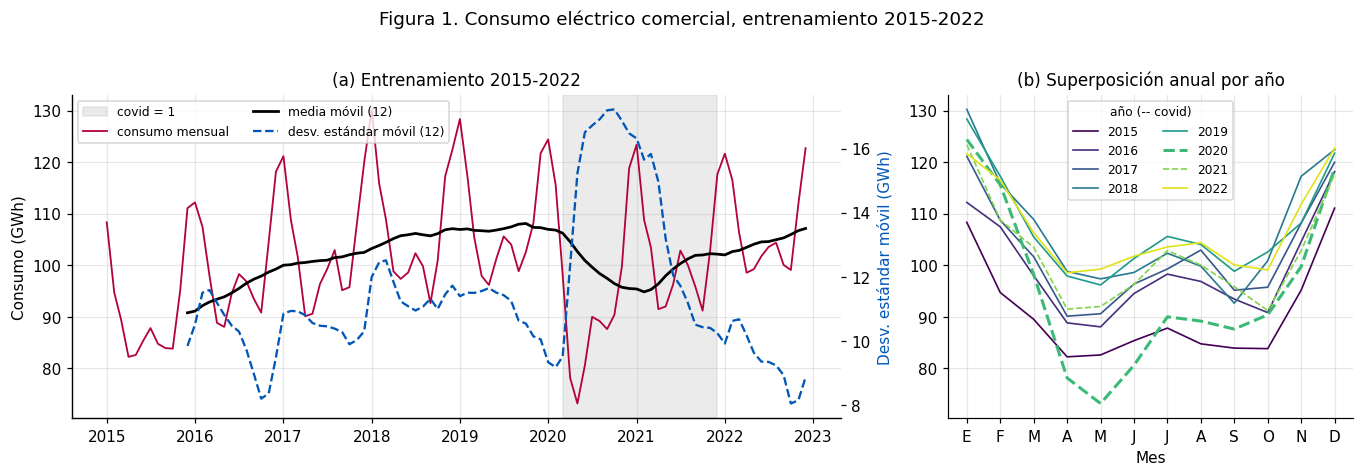

Box-Cox: λ = 0.004, IC 95 % [-1.45; 1.49] | contiene λ = 0: True | contiene λ = 1: True
Escala original, años sin covid: pendiente log(desv.) ~ log(media) = 0.25 (≈ 0: aditiva; ≈ 1: multiplicativa) | r(media, desv.) = 0.20
STL aditivo (GWh)  2015 → 2019: amplitud estacional 29.198 → 31.370 (+7.4 %) | nivel de tendencia 90.9 → 106.8 GWh (+17.4 %)
STL sobre log      2015 → 2019: amplitud estacional 0.303 → 0.287 (-5.1 %) | nivel de tendencia 90.5 → 106.3 GWh (+17.5 %)


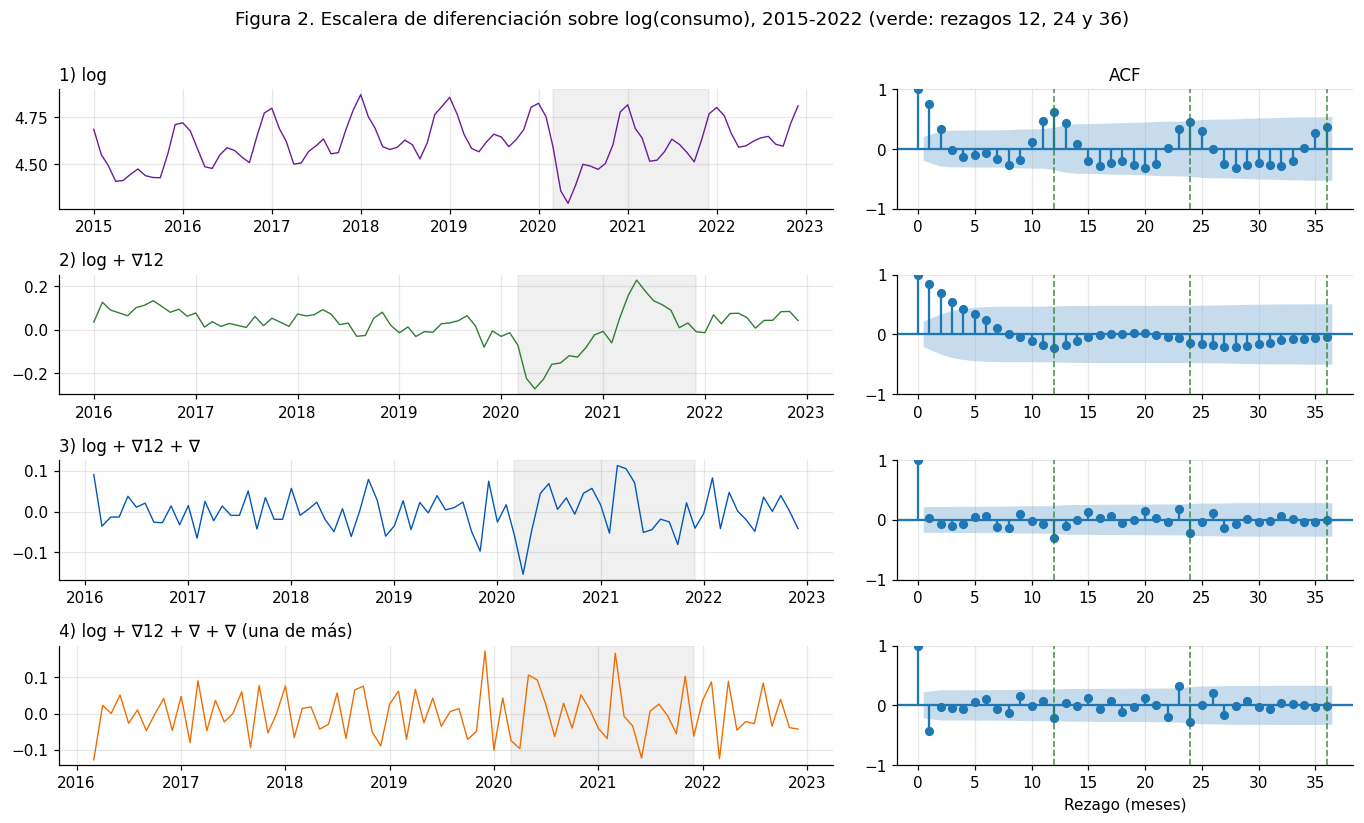

,n,ADF,p ADF,KPSS,p KPSS,varianza,ρ1,ρ12,veredicto (5 %)
serie,,,,,,,,,
0) original (GWh),96,-2.190,0.2098,0.259,≥ 0.100,1.45e+02,+0.750,+0.665,ambiguo
1) log,96,-2.354,0.1552,0.261,≥ 0.100,1.40e-02,+0.758,+0.621,ambiguo
2) log + ∇12,84,-2.563,0.1009,0.222,≥ 0.100,7.12e-03,+0.849,-0.228,ambiguo
2b) log + ∇,95,-2.667,0.0800,0.036,≥ 0.100,6.37e-03,+0.470,+0.757,ambiguo
3) log + ∇12 + ∇,83,-8.820,0.0000,0.040,≥ 0.100,2.17e-03,+0.032,-0.298,estacionaria
4) log + ∇12 + ∇ + ∇ (una de más),82,-7.251,0.0000,0.158,≥ 0.100,4.12e-03,-0.425,-0.208,estacionaria


Varianza: peldaño 2 → 3: -70 % | peldaño 3 → 4: +90 %


In [2]:
# Todo el análisis de esta sección usa solo y_train (2015-2022)
ly_train = np.log(y_train).rename("log_consumo")
covid = (df.index[df["covid"] == 1].min(), df.index[df["covid"] == 1].max())

# (a) Figura 1: nivel, dispersión y patrón estacional del entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.9, 1]})
ax = axes[0]
ax.axvspan(*covid, color=GRIS, alpha=0.2, label="covid = 1")
ax.plot(y_train.index, y_train, color=ROJO, lw=1.2, label="consumo mensual")
ax.plot(y_train.index, y_train.rolling(S).mean(), color="k", lw=1.8, label="media móvil (12)")
ax2 = ax.twinx()
ax2.plot(y_train.index, y_train.rolling(S).std(), color=AZUL, lw=1.5, ls="--", label="desv. estándar móvil (12)")
ax2.set_ylabel("Desv. estándar móvil (GWh)", color=AZUL); ax2.grid(False)
ax.set(ylabel="Consumo (GWh)", title="(a) Entrenamiento 2015-2022")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=2)
colores_anio = plt.cm.viridis(np.linspace(0, 0.95, y_train.index.year.nunique()))
for color, (anio, g) in zip(colores_anio, y_train.groupby(y_train.index.year)):
    axes[1].plot(g.index.month, g.values, color=color, lw=2.0 if anio == 2020 else 1.1,
                 ls="--" if anio in (2020, 2021) else "-", label=str(anio))
axes[1].set_xticks(range(1, 13), list("EFMAMJJASOND")); axes[1].set(xlabel="Mes", title="(b) Superposición anual por año")
axes[1].legend(ncol=2, title="año (-- covid)", title_fontsize=8)
fig.suptitle("Figura 1. Consumo eléctrico comercial, entrenamiento 2015-2022", y=1.02)
plt.tight_layout(); plt.show()

# (b) Transformación: λ de Box-Cox (MV), relación nivel-dispersión y contraste STL aditivo frente a STL sobre log
from statsmodels.tsa.seasonal import STL
lam, ic_lam = stats.boxcox(y_train.to_numpy(), alpha=0.05)[1:]
print(f"Box-Cox: λ = {lam:.3f}, IC 95 % [{ic_lam[0]:.2f}; {ic_lam[1]:.2f}] | contiene λ = 0: {ic_lam[0] < 0 < ic_lam[1]} | "
      f"contiene λ = 1: {ic_lam[0] < 1 < ic_lam[1]}")
anual = y_train[~y_train.index.year.isin([2020, 2021])].groupby(lambda t: t.year).agg(["mean", "std"])   # años sin covid
beta, _ = np.polyfit(np.log(anual["mean"]), np.log(anual["std"]), 1)
print(f"Escala original, años sin covid: pendiente log(desv.) ~ log(media) = {beta:.2f} (≈ 0: aditiva; ≈ 1: multiplicativa) | "
      f"r(media, desv.) = {np.corrcoef(anual['mean'], anual['std'])[0, 1]:.2f}")
for nombre, serie in [("STL aditivo (GWh)", y_train), ("STL sobre log", ly_train)]:
    stl = STL(serie, period=S, robust=True).fit()
    amp = stl.seasonal.groupby(serie.index.year).agg(lambda g: g.max() - g.min())       # amplitud estacional anual
    niv = np.exp(stl.trend) if nombre.endswith("log") else stl.trend
    niv = niv.groupby(serie.index.year).mean()
    print(f"{nombre:<18} 2015 → 2019: amplitud estacional {amp[2015]:.3f} → {amp[2019]:.3f} ({100 * (amp[2019] / amp[2015] - 1):+.1f} %) "
          f"| nivel de tendencia {niv[2015]:.1f} → {niv[2019]:.1f} GWh ({100 * (niv[2019] / niv[2015] - 1):+.1f} %)")

# (c) Escalera de diferenciación con ADF (H0: raíz unitaria) y KPSS (H0: estacionariedad en nivel)
def diagnostico_estacionariedad(serie, nombre, alpha=0.05):
    x = np.asarray(serie, dtype=float)
    adf_est, p_adf = adfuller(x, autolag="AIC")[:2]
    kpss_est, p_kpss = kpss(x, regression="c", nlags="auto")[:2]        # p acotado a [0,01; 0,10]
    veredicto = {(True, True): "estacionaria", (False, False): "no estacionaria",
                 (True, False): "ambiguo", (False, True): "ambiguo"}[(p_adf < alpha, p_kpss > alpha)]
    r = acf(x, nlags=S)
    return {"serie": nombre, "n": len(x), "ADF": adf_est, "p ADF": p_adf, "KPSS": kpss_est, "p KPSS": p_kpss,
            "varianza": float(np.var(x)), "ρ1": r[1], "ρ12": r[S], "veredicto (5 %)": veredicto}

escalera = [(y_train, "0) original (GWh)", ROJO), (ly_train, "1) log", MORADO),
            (ly_train.diff(S).dropna(), "2) log + ∇12", VERDE), (ly_train.diff(1).dropna(), "2b) log + ∇", GRIS),
            (ly_train.diff(S).diff(1).dropna(), "3) log + ∇12 + ∇", AZUL),
            (ly_train.diff(S).diff(1).diff(1).dropna(), "4) log + ∇12 + ∇ + ∇ (una de más)", NARANJA)]
graf = [e for e in escalera if e[1][:2] in ("1)", "2)", "3)", "4)")]
fig, axes = plt.subplots(len(graf), 2, figsize=(12.5, 7.4), gridspec_kw={"width_ratios": [1.7, 1]})
for fila, (serie, titulo, color) in enumerate(graf):
    axes[fila, 0].plot(serie.index, serie.to_numpy(), color=color, lw=0.9)
    axes[fila, 0].axvspan(*covid, color=GRIS, alpha=0.15); axes[fila, 0].set_title(titulo, loc="left")
    plot_acf(serie.to_numpy(), lags=36, ax=axes[fila, 1], title="ACF" if fila == 0 else "")
    for k in (12, 24, 36):
        axes[fila, 1].axvline(k, color=VERDE, ls="--", lw=1.1, alpha=0.8)
axes[-1, 1].set_xlabel("Rezago (meses)")
fig.suptitle("Figura 2. Escalera de diferenciación sobre log(consumo), 2015-2022 (verde: rezagos 12, 24 y 36)", y=1.005)
plt.tight_layout(); plt.show()

tabla_escalera = pd.DataFrame([diagnostico_estacionariedad(s_, t) for s_, t, _ in escalera]).set_index("serie")
p_kpss_txt = lambda p: "≥ 0.100" if p >= 0.1 else ("≤ 0.010" if p <= 0.01 else f"{p:.3f}")   # p tabulado acotado
display(tabla_escalera.style.format({"ADF": "{:.3f}", "p ADF": "{:.4f}", "KPSS": "{:.3f}", "p KPSS": p_kpss_txt,
                                     "varianza": "{:.2e}", "ρ1": "{:+.3f}", "ρ12": "{:+.3f}"})
        .set_caption("Tabla 1. ADF (H0: raíz unitaria) y KPSS (H0: estacionariedad en nivel) por peldaño, entrenamiento 2015-2022"))
v = tabla_escalera["varianza"]
print(f"Varianza: peldaño 2 → 3: {100 * (v.iloc[4] / v.iloc[2] - 1):+.0f} % | peldaño 3 → 4: {100 * (v.iloc[5] / v.iloc[4] - 1):+.0f} %")

**Transformación.** Los datos de entrenamiento no imponen el logaritmo. El λ de Box y Cox (1964) es 0,004, con IC 95 % [−1,45; 1,49] que incluye λ = 0 y λ = 1. En los años sin covid, la dispersión anual apenas se asocia con el nivel (pendiente log-log = 0,25; r = 0,20). Según STL, entre 2015 y 2019 la amplitud estacional crece 7,4 % en GWh y la tendencia 17,4 %, mientras que sobre log la amplitud cae 5,1 %: estructura intermedia. El logaritmo se mantiene por continuidad con la Semana 1 y porque expresa coeficientes y errores en términos relativos; la escala original no queda descartada.

**Serie en nivel.** En log, ADF (Dickey y Fuller, 1979; H0: raíz unitaria) no rechaza (p = 0,155) y KPSS (Kwiatkowski et al., 1992; H0: estacionariedad) tampoco (p ≥ 0,10): resultado no concluyente. La ACF decae lentamente (ρ1 = 0,758; ρ12 = 0,621; Fig. 2).

**Diferenciación.** Con solo ∇12, ADF no rechaza (p = 0,101) y ρ1 = 0,849; con solo ∇, ρ12 = 0,757 indica dependencia estacional persistente. Con ∇12 + ∇, ADF rechaza (p < 0,001), KPSS no rechaza y la varianza cae 70 % (Rosas, 2026). Otra diferencia regular eleva la varianza 90 % y lleva ρ1 a −0,425 (sobrediferenciación). Se fija d = 1, D = 1 y s = 12, la combinación mínima que ambas pruebas califican de estacionaria; D se revisa en la sección 2.

## 2. Identificación y estimación de modelos

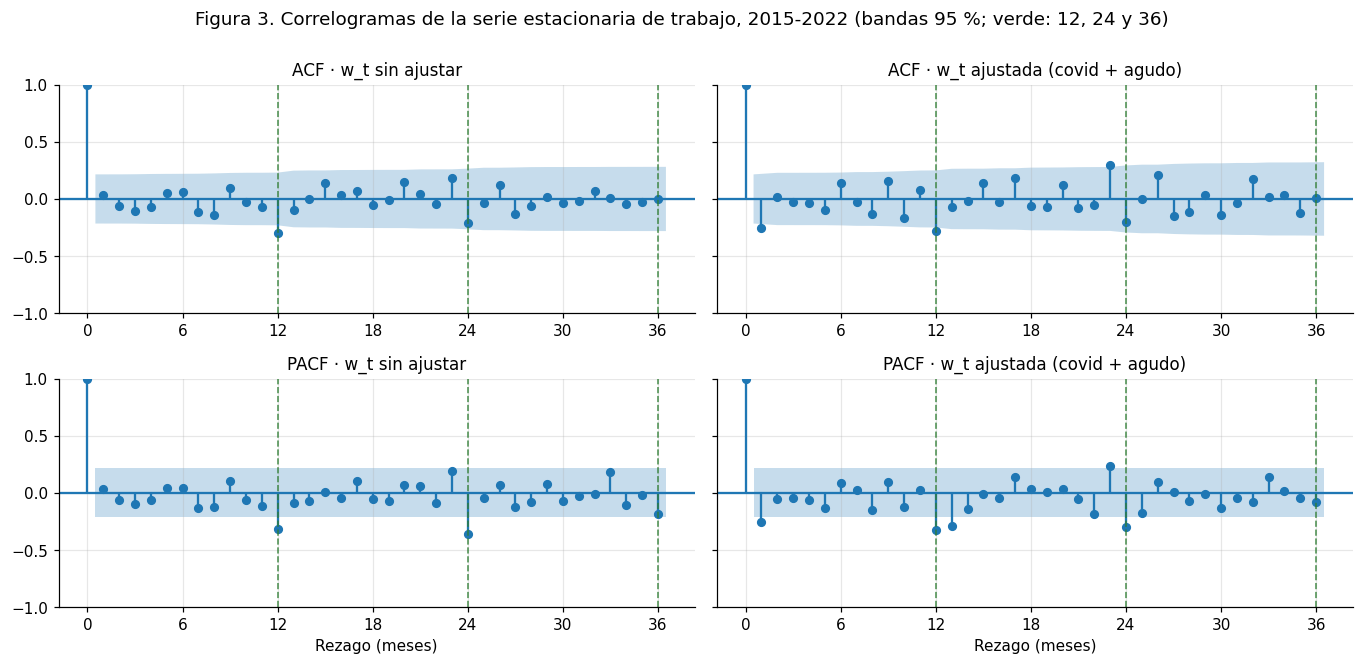

n = 83 | banda 95 % = ±0.215 | w_t afectadas por meses covid: 34 de 83 | efecto preliminar: covid = -0.055, agudo = -0.093
w_t        ACF  fuera de banda: {12: -0.298}
w_t        PACF fuera de banda: {12: -0.316, 24: -0.358}
w_t ajust. ACF  fuera de banda: {1: -0.256, 12: -0.281, 23: 0.293}
w_t ajust. PACF fuera de banda: {1: -0.256, 12: -0.329, 13: -0.293, 23: 0.236, 24: -0.299}


In [3]:
# --- Intervenciones históricas delimitadas retrospectivamente con datos de entrenamiento; nulas en 2023. ---
X = pd.DataFrame({"covid": df["covid"].astype(float),                                          # indicadora oficial del CSV
                  "agudo": ((df.index >= "2020-04-01") & (df.index <= "2020-06-01")).astype(float)},  # fase aguda (Formativa 2)
                 index=df.index)
X_train, X_val = X.loc[y_train.index], X.loc[y_val.index]
assert (X_val == 0).all().all(), "en 2023 las intervenciones valen 0: no introducen información futura"

# --- Serie estacionaria de trabajo w_t = (1-B)(1-B^12) log y_t, sin y con el shock descontado (solo train) ---
w = ly_train.diff(S).diff(1).dropna().rename("w")
pre = SARIMAX(ly_train, exog=X_train, order=(0, 1, 0), seasonal_order=(0, 1, 0, S)).fit(disp=False)   # efecto preliminar
w_aj = (ly_train - X_train @ pre.params[["covid", "agudo"]]).diff(S).diff(1).dropna().rename("w_aj")
meses_covid = df.index[df["covid"] == 1]
afectadas = sum(any(t - pd.DateOffset(months=k) in meses_covid for k in (0, 1, 12, 13)) for t in w.index)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.0), sharey=True)
for col, (serie, nombre) in enumerate([(w, "w_t sin ajustar"), (w_aj, "w_t ajustada (covid + agudo)")]):
    plot_acf(serie.to_numpy(), lags=36, ax=axes[0, col], title=f"ACF · {nombre}")
    plot_pacf(serie.to_numpy(), lags=36, ax=axes[1, col], method="ywm", title=f"PACF · {nombre}")
    for ax in axes[:, col]:
        for k in (12, 24, 36):
            ax.axvline(k, color=VERDE, ls="--", lw=1.1, alpha=0.8)
        ax.set_xticks(range(0, 37, 6))
axes[1, 0].set_xlabel("Rezago (meses)"); axes[1, 1].set_xlabel("Rezago (meses)")
fig.suptitle("Figura 3. Correlogramas de la serie estacionaria de trabajo, 2015-2022 (bandas 95 %; verde: 12, 24 y 36)", y=1.0)
plt.tight_layout(); plt.show()

banda = 1.96 / np.sqrt(len(w))
print(f"n = {len(w)} | banda 95 % = ±{banda:.3f} | w_t afectadas por meses covid: {afectadas} de {len(w)} | "
      f"efecto preliminar: covid = {pre.params['covid']:+.3f}, agudo = {pre.params['agudo']:+.3f}")
for serie, nombre in [(w, "w_t       "), (w_aj, "w_t ajust."), ]:
    ra, rp = acf(serie, nlags=36), pacf(serie, nlags=36, method="ywm")
    print(f"{nombre} ACF  fuera de banda:", {k: round(float(ra[k]), 3) for k in range(1, 37) if abs(ra[k]) > banda})
    print(f"{nombre} PACF fuera de banda:", {k: round(float(rp[k]), 3) for k in range(1, 37) if abs(rp[k]) > banda})

In [4]:
# --- Candidatos: (orden, orden estacional, intervenciones, lectura que lo origina) ---
CANDIDATOS = {
    "M1": ((0, 1, 0), (0, 1, 1, S), None,               "lectura directa de w_t: MA(1) estacional"),
    "M2": ((0, 1, 1), (0, 1, 1, S), None,               "agrega MA(1) regular (ρ1 de w_t ajustada)"),
    "M3": ((1, 1, 0), (0, 1, 1, S), None,               "alternativa AR(1) para el rezago 1"),
    "M4": ((0, 1, 0), (1, 1, 0, S), None,               "alternativa AR(1) estacional (PACF en 12)"),
    "M5": ((0, 1, 1), (0, 1, 1, S), ["covid"],          "M2 + indicadora oficial covid"),
    "M6": ((0, 1, 1), (0, 1, 1, S), ["covid", "agudo"], "M2 + covid + agudo (w_t ajustada)"),
}

def estimar(serie, orden, orden_est, exog=None, maxiter=200):
    """Estimación por máxima verosimilitud; devuelve el ajuste y el número de avisos de convergencia."""
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        fit = SARIMAX(serie, exog=exog, order=orden, seasonal_order=orden_est).fit(disp=False, maxiter=maxiter)
    return fit, sum(issubclass(a.category, ConvergenceWarning) for a in avisos)

def sin_parametro(orden, orden_est, param):
    """Órdenes del modelo restringido (param = 0) para la prueba de razón de verosimilitud (LR)."""
    (p, d, q), (P, D, Q, s) = orden, orden_est
    cambia = {"ar.L1": ((0, d, q), orden_est), "ma.L1": ((p, d, 0), orden_est),
              "ar.S.L12": (orden, (0, D, Q, s)), "ma.S.L12": (orden, (P, D, 0, s))}
    return cambia[param]

ajustes, filas = {}, []
for nombre, (orden, orden_est, cols, lectura) in CANDIDATOS.items():
    Xe = None if cols is None else X_train[cols]
    fit50, av50 = estimar(ly_train, orden, orden_est, Xe, maxiter=50)
    fit, av = estimar(ly_train, orden, orden_est, Xe, maxiter=200)
    ajustes[nombre] = fit
    ok = lambda f, a: "sí" if f.mle_retvals.get("converged", True) and a == 0 else "NO"
    fila = {"modelo": nombre, "especificación": f"SARIMA{orden}{orden_est[:3]}12" + ("" if cols is None else " + " + " + ".join(cols)),
            "función": lectura, "k": len(fit.params) - 1, "conv. 50/200": f"{ok(fit50, av50)}/{ok(fit, av)}",
            "|raíz| mín": np.concatenate([np.abs(fit.arroots), np.abs(fit.maroots)]).min()}
    for p in fit.param_names[:-1]:                                     # coeficiente (p-valor: LR para ARMA, Wald para X)
        if p.startswith(("ar.", "ma.")):
            restr, _ = estimar(ly_train, *sin_parametro(orden, orden_est, p), Xe)
            pv = stats.chi2.sf(max(2 * (fit.llf - restr.llf), 0), 1)
        else:
            pv = fit.pvalues[p]
        fila[p] = f"{fit.params[p]:+.3f} ({pv:.3f})"
    filas.append(fila)
tabla_est = pd.DataFrame(filas).set_index("modelo")
cols_par = [c for c in ["covid", "agudo", "ar.L1", "ma.L1", "ar.S.L12", "ma.S.L12"] if c in tabla_est]
display(tabla_est[["especificación", "función", "k", "conv. 50/200", "|raíz| mín"] + cols_par]
        .fillna("—").style.format({"|raíz| mín": "{:.4f}"})
        .set_caption("Tabla 2. Estimación por MV con 2015-2022 (n efectivo = 83): coeficiente (p-valor LR o Wald)"))
m6 = ajustes["M6"]
alt = m6.model.fit(disp=False, maxiter=200, cov_type="approx")       # covarianza por Hessiano numérico
lr_theta = stats.chi2.sf(2 * (m6.llf - estimar(ly_train, (0, 1, 1), (0, 1, 0, S), X_train[["covid", "agudo"]])[0].llf), 1)
print(f"M6 · Θ1 = {m6.params['ma.S.L12']:+.4f} | p Wald (OPG) = {m6.pvalues['ma.S.L12']:.3f} | "
      f"p Wald (Hessiano numérico) = {alt.pvalues['ma.S.L12']:.1e} | p LR = {lr_theta:.1e} | p Wald de σ² (OPG) = {m6.pvalues['sigma2']:.3f}")
desvio = np.exp(m6.params[["covid", "agudo"]].cumsum()) - 1
print(f"Desviación estimada del nivel en M6: {100 * desvio['covid']:.1f} % en los meses covid = 1 y "
      f"{100 * desvio['agudo']:.1f} % en abril-junio de 2020 (covid + agudo)")
print("Ecuación de M6 (Conclusiones): " + " | ".join(f"{p} = {m6.params[p]:+.4f}" for p in m6.param_names[:-1])
      + f" | sigma2 = {m6.params['sigma2']:.2e}")

# Contraste ante Θ1 ≈ −1: estacionalidad determinista (D = 0, indicadoras mensuales) con la misma intervención, solo train
MESES = pd.get_dummies(df.index.month, prefix="mes", dtype=float).iloc[:, 1:].set_index(df.index)
m6_det, av_det = estimar(ly_train, (0, 1, 1), (0, 0, 0, 0), pd.concat([X_train, MESES.loc[y_train.index]], axis=1))
r_det = pd.Series(np.asarray(m6_det.resid), index=ly_train.index).iloc[1:]
lb_det = acorr_ljungbox(r_det, lags=[12, 24], model_df=1, return_df=True)["lb_pvalue"]
print(f"Contraste D = 0 (ARIMA(0,1,1) + 11 indicadoras mensuales + covid + agudo): θ1 = {m6_det.params['ma.L1']:+.3f} | "
      f"avisos de convergencia: {av_det} | Ljung-Box residuos de entrenamiento: p(K=12) = {lb_det[12]:.3f}, p(K=24) = {lb_det[24]:.3f} "
      f"| AIC no comparable con D = 1")

,especificación,función,k,conv. 50/200,|raíz| mín,covid,agudo,ar.L1,ma.L1,ar.S.L12,ma.S.L12
modelo,,,,,,,,,,,
M1,"SARIMA(0, 1, 0)(0, 1, 1)12",lectura directa de w_t: MA(1) estacional,1,sí/sí,1.0015,—,—,—,—,—,-0.982 (0.000)
M2,"SARIMA(0, 1, 1)(0, 1, 1)12",agrega MA(1) regular (ρ1 de w_t ajustada),2,sí/sí,1.0024,—,—,—,-0.051 (0.689),—,-0.971 (0.000)
M3,"SARIMA(1, 1, 0)(0, 1, 1)12",alternativa AR(1) para el rezago 1,2,sí/sí,1.0018,—,—,-0.044 (0.696),—,—,-0.979 (0.000)
M4,"SARIMA(0, 1, 0)(1, 1, 0)12",alternativa AR(1) estacional (PACF en 12),1,sí/sí,1.1022,—,—,—,—,-0.311 (0.004),—
M5,"SARIMA(0, 1, 1)(0, 1, 1)12 + covid",M2 + indicadora oficial covid,3,sí/sí,1.0016,-0.062 (0.000),—,—,-0.205 (0.159),—,-0.981 (0.000)
M6,"SARIMA(0, 1, 1)(0, 1, 1)12 + covid + agudo",M2 + covid + agudo (w_t ajustada),4,NO/sí,1.0026,-0.058 (0.000),-0.129 (0.000),—,-0.462 (0.000),—,-0.969 (0.000)


M6 · Θ1 = -0.9688 | p Wald (OPG) = 0.487 | p Wald (Hessiano numérico) = 1.4e-11 | p LR = 1.2e-09 | p Wald de σ² (OPG) = 0.469
Desviación estimada del nivel en M6: -5.6 % en los meses covid = 1 y -17.1 % en abril-junio de 2020 (covid + agudo)
Contraste D = 0 (ARIMA(0,1,1) + 11 indicadoras mensuales + covid + agudo): θ1 = -0.430 | avisos de convergencia: 0 | Ljung-Box residuos de entrenamiento: p(K=12) = 0.128, p(K=24) = 0.001 | AIC no comparable con D = 1


**Candidatos principales (ACF/PACF).** Sobre $w_t = \nabla\nabla_{12}\log y_t$ (n = 83, banda ±0,215), la ACF solo supera la banda en el rezago 12 (−0,298) y la PACF en 12 y 24: patrón de MA(1) estacional sin estructura regular (Hyndman y Athanasopoulos, 2021). **M1** recoge esa lectura y **M4** la alternativa, un AR(1) estacional (PACF en 12). Al descontar un efecto preliminar del shock, que afecta 34 de 83 valores de $w_t$, aparece el rezago 1 (ACF = PACF = −0,256), que motiva **M2** (MA regular) y **M3** (AR regular).

**Extensiones con intervención.** **M5** y **M6** no nacen solo de los correlogramas: agregan a M2 información externa (Box y Tiao, 1975), la indicadora oficial `covid` y, en M6, `agudo` (abril–junio de 2020), delimitada retrospectivamente. En M6 el nivel se desvía −5,6 % en meses `covid` y −17,1 % en abril–junio de 2020; descriptivas, no causales.

**Estimación.** Con 200 iteraciones todos convergen (M6 no lo logra con 50); los MA estacionales quedan a menos de 0,003 de la frontera de invertibilidad. El MA regular solo es significativo con `covid` y `agudo` (θ1 = −0,462; p LR < 0,001).

**Θ1 = −0,969 en M6.** El p de Wald es 0,487 con OPG y < 0,001 con Hessiano numérico, y la LR rechaza Θ1 = 0: los p-valores son indicativos. Esto sugiere estacionalidad determinista o sobrediferenciación estacional, pero con D = 0 persiste autocorrelación (Ljung-Box K = 24, p = 0,001), por lo que se mantiene D = 1.

## 3. Selección y comparación de modelos

Naive estacional — RMSE: 7.26 | MAE: 6.53


,k,AIC,ΔAIC,BIC,ΔBIC,AICc,RMSE,MAE,ME,MAPE (%),MASE,cobertura IC95 (%)
modelo,,,,,,,,,,,,
M1,1,-300.05,31.31,-295.21,24.05,-299.90,7.20,6.71,6.71,5.97,1.03,100.00
M2,2,-298.21,33.15,-290.95,28.31,-297.90,7.07,6.56,6.56,5.84,1.01,100.00
M3,2,-298.20,33.16,-290.94,28.32,-297.90,7.09,6.58,6.58,5.86,1.01,100.00
M4,1,-277.81,53.55,-272.97,46.29,-277.66,4.12,3.71,3.21,3.21,0.57,100.00
M5,3,-300.90,30.45,-291.23,28.03,-300.39,6.85,6.40,6.40,5.69,0.98,100.00
M6,4,-331.36,0.00,-319.26,0.00,-330.58,5.71,5.20,5.20,4.60,0.80,100.00
Naive estacional,No aplica,No aplica,No aplica,No aplica,No aplica,No aplica,7.26,6.53,6.53,5.64,1.00,No aplica
Naive estacional con deriva,No aplica,No aplica,No aplica,No aplica,No aplica,No aplica,4.72,4.22,3.55,3.63,0.65,No aplica


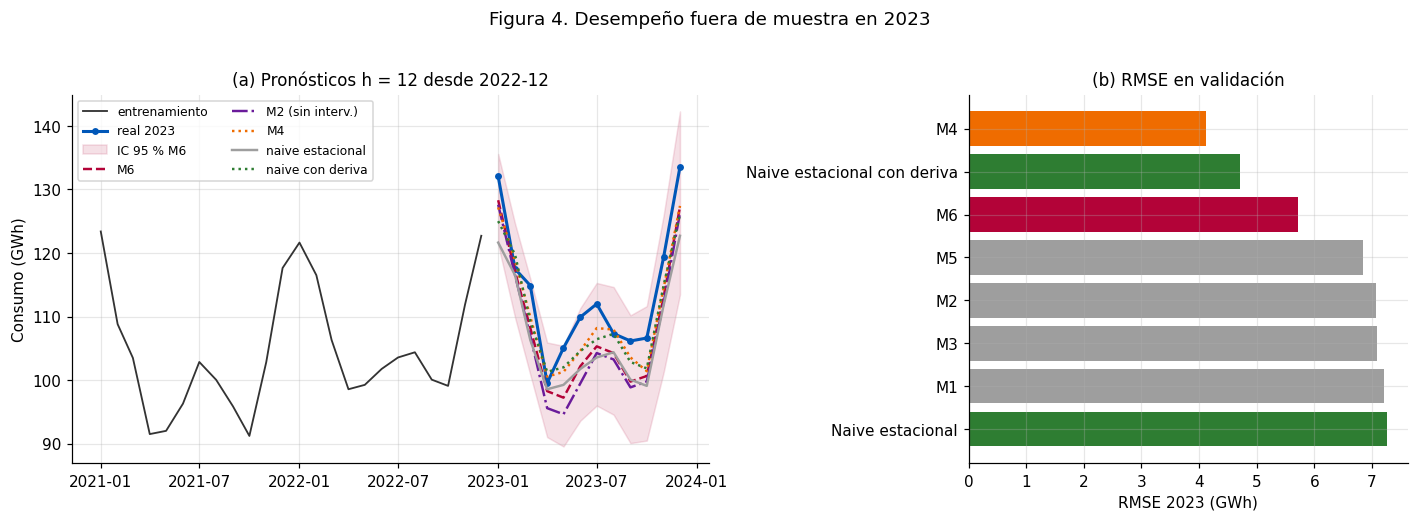

Crecimiento 2023 / 2022 (media anual): real = +6.1 % | M2 = +0.0 % | M4 = +3.1 % | M6 = +1.2 % | deriva naive = +2.8 %
Meses de 2023 subestimados por M6: 12 de 12 | reducción frente al naive estacional: RMSE 21.4 %, MAE 20.3 % | M4 frente al naive estacional: RMSE 43.2 %, MAE 43.2 %


In [5]:
# Referencia obligatoria: naive estacional (repite el valor del mismo mes del año anterior)
naive_val = y["2022-01":"2022-12"].to_numpy()
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
mae  = lambda e: float(np.mean(np.abs(e)))
print(f"Naive estacional — RMSE: {rmse(y_val.to_numpy() - naive_val):.2f} | MAE: {mae(y_val.to_numpy() - naive_val):.2f}")

# --- AIC, BIC, RMSE y MAE en validación 2023 para los candidatos (pronóstico h = 12 desde 2022-12) ---
real = y_val.to_numpy()
denom_mase = mae(y_train.to_numpy()[S:] - y_train.to_numpy()[:-S])          # naive estacional dentro de train
g_medio = np.mean(y_train.to_numpy()[S:] / y_train.to_numpy()[:-S] - 1)     # crecimiento interanual medio (train)
naive_deriva = naive_val * (1 + g_medio)

def pronosticar(fit, exog_futuro=None):
    """Pronóstico en GWh: media con corrección de sesgo exp(m + v/2) e IC 95 % retransformado."""
    f = fit.get_forecast(steps=len(y_val), exog=exog_futuro)
    m, v = np.asarray(f.predicted_mean), np.asarray(f.var_pred_mean)
    ic = np.exp(np.asarray(f.conf_int()))
    return {"media": np.exp(m + v / 2), "inferior": ic[:, 0], "superior": ic[:, 1]}

def metricas(pred):
    e = real - pred
    return {"RMSE": rmse(e), "MAE": mae(e), "ME": e.mean(), "MAPE (%)": 100 * np.mean(np.abs(e / real)), "MASE": mae(e) / denom_mase}

pronos, filas = {}, []
for nombre, fit in ajustes.items():
    cols = CANDIDATOS[nombre][2]
    pr = pronos[nombre] = pronosticar(fit, None if cols is None else X_val[cols])
    filas.append({"modelo": nombre, "k": len(fit.params) - 1, "AIC": fit.aic, "BIC": fit.bic, "AICc": fit.aicc,
                  **metricas(pr["media"]), "cobertura IC95 (%)": 100 * np.mean((real >= pr["inferior"]) & (real <= pr["superior"]))})
filas += [{"modelo": "Naive estacional", **metricas(naive_val)}, {"modelo": "Naive estacional con deriva", **metricas(naive_deriva)}]
tabla_comp = pd.DataFrame(filas).set_index("modelo")
tabla_comp.insert(2, "ΔAIC", tabla_comp["AIC"] - tabla_comp["AIC"].min())
tabla_comp.insert(4, "ΔBIC", tabla_comp["BIC"] - tabla_comp["BIC"].min())
tabla_comp["k"] = tabla_comp["k"].astype("Int64")
# Vista de la Tabla 3: los criterios exigidos por la rúbrica primero; el resto, como complemento (mismos valores)
RUBRICA = ["k", "AIC", "ΔAIC", "BIC", "ΔBIC", "RMSE", "MAE"]
COMPLEMENTO = ["AICc", "ME", "MAPE (%)", "MASE", "cobertura IC95 (%)"]
vista_comp = tabla_comp[RUBRICA + COMPLEMENTO].copy()
vista_comp.columns = pd.MultiIndex.from_tuples([("Criterios de la rúbrica", c) for c in RUBRICA]
                                               + [("Complementarias (sin puntaje)", c) for c in COMPLEMENTO])
display(vista_comp.style.format(precision=2, na_rep="No aplica")
        .set_caption("Tabla 3. Ajuste penalizado (2015-2022) y error de pronóstico en validación 2023 (GWh)"))

FINAL = "M6"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.45, 1]})
ax = axes[0]
ax.plot(y_train["2021-01":].index, y_train["2021-01":], color="#333333", lw=1.2, label="entrenamiento")
ax.plot(y_val.index, real, color=AZUL, lw=2, marker="o", ms=3.5, label="real 2023")
ax.fill_between(y_val.index, pronos[FINAL]["inferior"], pronos[FINAL]["superior"], color=ROJO, alpha=0.12, label="IC 95 % M6")
for nombre, pred, color, ls in [("M6", pronos["M6"]["media"], ROJO, "--"), ("M2 (sin interv.)", pronos["M2"]["media"], MORADO, "-."),
                                ("M4", pronos["M4"]["media"], NARANJA, ":"), ("naive estacional", naive_val, GRIS, "-"),
                                ("naive con deriva", naive_deriva, VERDE, ":")]:
    ax.plot(y_val.index, pred, color=color, ls=ls, lw=1.6, label=nombre)
ax.set(ylabel="Consumo (GWh)", title="(a) Pronósticos h = 12 desde 2022-12"); ax.legend(ncol=2, loc="upper left")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7))); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
orden_b = tabla_comp["RMSE"].sort_values()
axes[1].barh(range(len(orden_b)), orden_b, color=[ROJO if m == FINAL else NARANJA if m == "M4" else (VERDE if m.startswith("Naive") else GRIS)
                                                   for m in orden_b.index])
axes[1].set_yticks(range(len(orden_b)), list(orden_b.index)); axes[1].invert_yaxis()
axes[1].set(xlabel="RMSE 2023 (GWh)", title="(b) RMSE en validación")
fig.suptitle("Figura 4. Desempeño fuera de muestra en 2023", y=1.02)
plt.tight_layout(); plt.show()

media_22 = y_train["2022"].mean()
print(f"Crecimiento 2023 / 2022 (media anual): real = {100 * (real.mean() / media_22 - 1):+.1f} % | "
      + " | ".join(f"{m} = {round(100 * (pronos[m]['media'].mean() / media_22 - 1), 1) + 0:+.1f} %" for m in ("M2", "M4", "M6"))
      + f" | deriva naive = {100 * g_medio:+.1f} %")
print(f"Meses de 2023 subestimados por {FINAL}: {int((real > pronos[FINAL]['media']).sum())} de 12 | "
      f"reducción frente al naive estacional: RMSE {100 * (1 - tabla_comp.loc[FINAL, 'RMSE'] / tabla_comp.loc['Naive estacional', 'RMSE']):.1f} %, "
      f"MAE {100 * (1 - tabla_comp.loc[FINAL, 'MAE'] / tabla_comp.loc['Naive estacional', 'MAE']):.1f} % | M4 frente al naive estacional: "
      f"RMSE {100 * (1 - tabla_comp.loc['M4', 'RMSE'] / tabla_comp.loc['Naive estacional', 'RMSE']):.1f} %, "
      f"MAE {100 * (1 - tabla_comp.loc['M4', 'MAE'] / tabla_comp.loc['Naive estacional', 'MAE']):.1f} %")

**Comparabilidad.** Los candidatos comparten muestra, logaritmo, d y D: sus AIC y BIC son comparables (Burnham y Anderson, 2004). RMSE y MAE se calculan en GWh, con retransformación corregida por sesgo, $\exp(\hat\mu_h + \hat\sigma_h^2/2)$ (Hyndman y Athanasopoulos, 2021).

**A favor de M6.** Minimiza AIC (−331,36) y BIC (−319,26); M4 queda a ΔAIC = 53,55, con mayor desviación residual (0,0444 frente a 0,0311; Tabla 4). Su MA estacional es el que sugieren los correlogramas; reduce el error del naive estacional en 21,4 % (RMSE) y 20,3 % (MAE).

**A favor de M4.** Tiene el menor error en 2023 (RMSE = 4,12; MAE = 3,71 GWh, frente a 5,71 y 5,20 de M6) y un diagnóstico residual algo más favorable a 24 rezagos (Ljung-Box p = 0,059 frente a 0,040). El naive con deriva (4,72; 4,22) también supera a M6. El consumo creció 6,1 % en 2023; M4 proyectó 3,1 % y M6, 1,2 %.

**Decisión.** Ningún candidato domina en todos los criterios: la selección es un compromiso entre ajuste dentro de muestra y desempeño fuera de muestra. M6 se mantiene como modelo de análisis por su mejor ajuste dentro de muestra y por incorporar las intervenciones del periodo COVID-19; M4 se conserva como alternativa predictiva. Con las intervenciones de M6, M4 empeora (RMSE = 7,79; sección 4): no son compatibles con su especificación. Con un único origen de validación no hay evidencia suficiente para declarar un modelo dominante; la decisión debe confirmarse con origen móvil.

## 4. Diagnóstico de residuos y validación de supuestos

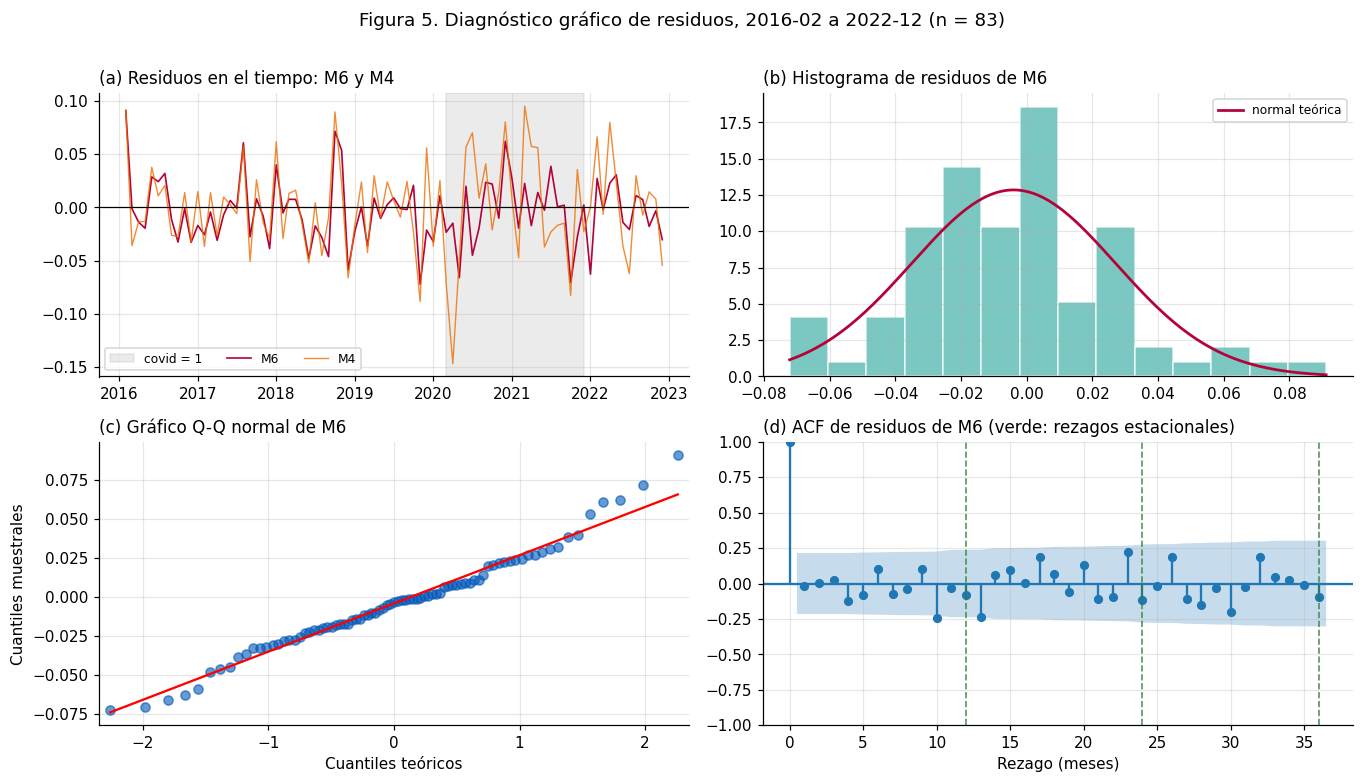

,Hipótesis nula (H0),M6 (seleccionado),M4,M2 (sin intervención)
Ljung-Box K = 12,ausencia de autocorrelación conjunta hasta el rezago 12,0.340 (gl 10),0.679 (gl 11),0.594 (gl 10)
Ljung-Box K = 24,ausencia de autocorrelación conjunta hasta el rezago 24,0.040 (gl 22) ✗,0.059 (gl 23),0.212 (gl 22)
Jarque-Bera,los residuos siguen una distribución normal,0.227,0.564,0.005 ✗
Shapiro-Wilk,los residuos siguen una distribución normal,0.279,0.392,0.018 ✗
ARCH-LM (12 rezagos),ausencia de efectos ARCH hasta los rezagos evaluados,0.825,0.786,0.576
Goldfeld-Quandt,igualdad de varianzas entre los dos grupos evaluados,0.659,0.017 ✗,0.203
t de Student,media residual igual a cero,0.246,0.986,0.678
desv. estándar residual (log),No aplica (medida descriptiva),0.0311,0.0444,0.0383


M6 · ACF residual fuera de ±0.215: {10: -0.245, 13: -0.238, 23: 0.221} | curtosis (exceso) = +0.634 | Goldfeld-Quandt M4: F = 2.22 (varianza 2.ª/1.ª mitad)
Ampliaciones de M6 → AIC | p Ljung-Box K = 24: {'M6 (1,1,1)(0,1,1)': '-329.70 | 0.034', 'M6 (0,1,2)(0,1,1)': '-329.69 | 0.038', 'M6 (0,1,1)(1,1,1)': '-329.62 | 0.022'}
M4 + covid + agudo → AIC = -296.94 | p Goldfeld-Quandt = 0.406 | p Ljung-Box K = 12 / 24 = 0.007 / 0.000 | RMSE 2023 = 7.79 | MAE 2023 = 7.31 | avisos: 0


In [6]:
# --- Misma batería para M6 (seleccionado), M4 (menor error en 2023) y M2 (M6 sin intervención); todos estimados con 2015-2022 ---
n_descartar = 1 + 1 * S                       # d + D·s residuos de arranque del filtro de Kalman
def residuos(fit):
    return pd.Series(np.asarray(fit.resid), index=ly_train.index).iloc[n_descartar:]

PRUEBAS = ["Ljung-Box K = 12", "Ljung-Box K = 24", "Jarque-Bera", "Shapiro-Wilk", "ARCH-LM (12 rezagos)", "Goldfeld-Quandt", "t de Student"]
H0 = ["ausencia de autocorrelación conjunta hasta el rezago 12", "ausencia de autocorrelación conjunta hasta el rezago 24",
      "los residuos siguen una distribución normal", "los residuos siguen una distribución normal",
      "ausencia de efectos ARCH hasta los rezagos evaluados", "igualdad de varianzas entre los dos grupos evaluados",
      "media residual igual a cero"]
def bateria(fit):
    r = residuos(fit); m_arma = sum(p.startswith(("ar.", "ma.")) for p in fit.param_names)
    lb = acorr_ljungbox(r, lags=[12, 24], model_df=m_arma, return_df=True)        # gl = K − (p + q + P + Q)
    gq = het_goldfeldquandt(r.to_numpy(), np.ones((len(r), 1)), split=0.5, drop=0.1, alternative="two-sided")
    p = [lb.loc[12, "lb_pvalue"], lb.loc[24, "lb_pvalue"], stats.jarque_bera(r).pvalue, stats.shapiro(r).pvalue,
         het_arch(r.to_numpy(), nlags=12)[1], gq[1], stats.ttest_1samp(r, 0.0).pvalue]
    gl = [f" (gl {12 - m_arma})", f" (gl {24 - m_arma})"] + [""] * 5
    return [f"{pv:.3f}{g}{' ✗' if pv <= 0.05 else ''}" for pv, g in zip(p, gl)] + [f"{r.std():.4f}"], p, gq[0]

final = ajustes[FINAL]
res = residuos(final)
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.0))
axes[0, 0].axvspan(*covid, color=GRIS, alpha=0.2, label="covid = 1")
axes[0, 0].plot(res.index, res, color=ROJO, lw=1.1, label="M6")
axes[0, 0].plot(res.index, residuos(ajustes["M4"]), color=NARANJA, lw=0.9, alpha=0.8, label="M4")
axes[0, 0].axhline(0, color="k", lw=0.8)
axes[0, 0].set_title("(a) Residuos en el tiempo: M6 y M4", loc="left"); axes[0, 0].legend(ncol=3)
axes[0, 1].hist(res, bins=14, density=True, color="#4db6ac", alpha=0.75, edgecolor="white")
xx = np.linspace(res.min(), res.max(), 200)
axes[0, 1].plot(xx, stats.norm.pdf(xx, res.mean(), res.std()), color=ROJO, lw=1.8, label="normal teórica")
axes[0, 1].set_title("(b) Histograma de residuos de M6", loc="left"); axes[0, 1].legend()
sm.qqplot(res.to_numpy(), line="s", ax=axes[1, 0], markerfacecolor=AZUL, markeredgecolor=AZUL, alpha=0.6)
axes[1, 0].set_title("(c) Gráfico Q-Q normal de M6", loc="left"); axes[1, 0].set(xlabel="Cuantiles teóricos", ylabel="Cuantiles muestrales")
plot_acf(res.to_numpy(), lags=36, ax=axes[1, 1], title="")
for k in (12, 24, 36):
    axes[1, 1].axvline(k, color=VERDE, ls="--", lw=1.1, alpha=0.8)
axes[1, 1].set_title("(d) ACF de residuos de M6 (verde: rezagos estacionales)", loc="left"); axes[1, 1].set_xlabel("Rezago (meses)")
fig.suptitle(f"Figura 5. Diagnóstico gráfico de residuos, 2016-02 a 2022-12 (n = {len(res)})", y=1.01)
plt.tight_layout(); plt.show()

resultados = {m: bateria(ajustes[m]) for m in ("M6", "M4", "M2")}
tabla_diag = pd.DataFrame({"Hipótesis nula (H0)": H0 + ["No aplica (medida descriptiva)"],
                           **{f"{m}{' (seleccionado)' if m == FINAL else ' (sin intervención)' if m == 'M2' else ''}": v[0]
                              for m, v in resultados.items()}},
                          index=PRUEBAS + ["desv. estándar residual (log)"])
# Vista de la Tabla 4: primero las pruebas mínimas de la rúbrica; el resto, como complemento (mismos valores)
MINIMAS = ["Ljung-Box K = 12", "Ljung-Box K = 24", "Jarque-Bera", "ARCH-LM (12 rezagos)"]
orden_filas = MINIMAS + [f for f in tabla_diag.index if f not in MINIMAS]
tabla_diag = tabla_diag.loc[orden_filas]
tabla_diag.index = pd.MultiIndex.from_tuples([("Mínimas (rúbrica)" if f in MINIMAS else "Complementarias", f) for f in orden_filas])
display(tabla_diag.style.set_caption("Tabla 4. p-valores de la batería de residuos, estimación 2015-2022 (✗: rechaza H0 al 5 %; "
                                     "Ljung-Box con gl = K − parámetros ARMA)"))

ra = acf(res, nlags=36); banda_r = 1.96 / np.sqrt(len(res))
print(f"M6 · ACF residual fuera de ±{banda_r:.3f}:", {k: round(float(ra[k]), 3) for k in range(1, 37) if abs(ra[k]) > banda_r},
      f"| curtosis (exceso) = {stats.kurtosis(res):+.3f} | Goldfeld-Quandt M4: F = {resultados['M4'][2]:.2f} (varianza 2.ª/1.ª mitad)")
# Respuestas a deficiencias detectadas con entrenamiento: Ljung-Box K = 24 en M6 y Goldfeld-Quandt en M4
extensiones = {"M6 (1,1,1)(0,1,1)": ((1, 1, 1), (0, 1, 1, S)), "M6 (0,1,2)(0,1,1)": ((0, 1, 2), (0, 1, 1, S)),
               "M6 (0,1,1)(1,1,1)": ((0, 1, 1), (1, 1, 1, S))}
print("Ampliaciones de M6 → AIC | p Ljung-Box K = 24:", {
      n: f"{f.aic:.2f} | {bateria(f)[1][1]:.3f}" for n, f in ((n, estimar(ly_train, o, so, X_train)[0]) for n, (o, so) in extensiones.items())})
m4_int, av4 = estimar(ly_train, (0, 1, 0), (1, 1, 0, S), X_train)
p4 = bateria(m4_int)[1]
pr4 = pronosticar(m4_int, X_val)
print(f"M4 + covid + agudo → AIC = {m4_int.aic:.2f} | p Goldfeld-Quandt = {p4[5]:.3f} | p Ljung-Box K = 12 / 24 = {p4[0]:.3f} / {p4[1]:.3f} | "
      f"RMSE 2023 = {rmse(real - pr4['media']):.2f} | MAE 2023 = {mae(real - pr4['media']):.2f} | avisos: {av4}")

Pruebas mínimas sobre los 83 residuos de M6, tras descartar los d + D·s = 13 iniciales del filtro de Kalman; M4 y M2 sirven de contraste.

**Autocorrelación.** Ljung-Box (Ljung y Box, 1978; H0: sin autocorrelación conjunta) no rechaza en K = 12 (p = 0,340; gl = 10), pero sí en K = 24 (p = 0,040; gl = 22). La ACF residual supera la banda en 10, 13 y 23 (|r| ≤ 0,245). Ampliar M6 eleva el AIC sin eliminar el rechazo (p ≤ 0,038).

**Normalidad.** Jarque-Bera (Jarque y Bera, 1987) no rechaza (p = 0,227), sin que ello demuestre normalidad; Shapiro-Wilk (Shapiro y Wilk, 1965) coincide (p = 0,279). El Q-Q muestra una cola superior algo pesada (Fig. 5c).

**Homocedasticidad.** ARCH-LM (Engle, 1982) no detecta efectos ARCH hasta 12 rezagos (p = 0,825), lo que no excluye otras formas de heterocedasticidad.

**Validez.** M6 se mantiene como modelo seleccionado, pero el rechazo de Ljung-Box en K = 24 indica que sus residuos no son ruido blanco: el modelo no extrae toda la dependencia de la serie y sus intervalos, que suponen errores independientes, deben leerse con cautela.

**Contraste.** M4 no rechaza ninguna prueba mínima al 5 % (Ljung-Box K = 24: p = 0,059, en el límite); solo rechaza Goldfeld-Quandt (p = 0,017), prueba complementaria cuya mayor varianza coincide con el shock de 2020 (Fig. 5a). M2 rechaza normalidad (Jarque-Bera p = 0,005): la intervención parece absorber los residuos extremos del shock.

## Conclusiones

1. **Transformación y diferenciación.** Se trabajó con log(consumo), d = 1 y D = 1 (s = 12). El logaritmo se eligió por interpretabilidad relativa, ya que Box-Cox y STL no lo distinguen de la escala original; ∇∇₁₂ es la combinación mínima que ADF y KPSS califican de estacionaria, y d = 2 sobrediferencia.
2. **Candidatos.** M1–M4 provienen de la lectura de la ACF y la PACF; M5 y M6 extienden M2 con intervenciones del periodo COVID-19.
3. **Modelo seleccionado.** M6, estimado con 2015–2022 como regresión con errores SARIMA(0,1,1)(0,1,1)₁₂ (coeficientes de la Tabla 2; los de intervención son descriptivos, no causales):

$$\log y_t = -0{,}058\,\texttt{covid}_t - 0{,}129\,\texttt{agudo}_t + n_t,$$
$$(1-B)(1-B^{12})\,n_t = (1 - 0{,}462B)(1 - 0{,}969B^{12})\,\varepsilon_t, \qquad \varepsilon_t \sim \mathrm{RB}(0, \sigma^2).$$

4. **Ajuste frente a predicción.** Ningún modelo domina en todos los criterios. M6 tiene el mejor ajuste dentro de muestra (AIC y BIC) e incorpora explícitamente las intervenciones del periodo COVID-19; M4 pronostica mejor 2023 (RMSE = 4,12 frente a 5,71 GWh) y su diagnóstico residual es algo más favorable a 24 rezagos. Ambos superan al naive estacional (7,26). M6 se mantiene como modelo de análisis y M4 como alternativa predictiva.
5. **Diagnóstico.** En M6 no se rechazan normalidad (Jarque-Bera) ni efectos ARCH; Ljung-Box no rechaza en K = 12, pero sí en K = 24 (p = 0,040).
6. **Limitación principal.** M6 conserva autocorrelación residual y subestima los 12 meses de 2023 (ME = +5,20 GWh); `agudo` se delimitó retrospectivamente. Antes de usarlo para comprometer energía, la comparación con M4 debe repetirse con validación de origen móvil.

## Referencias (APA)

Box, G. E. P., y Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological)*, *26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x

Box, G. E. P., y Tiao, G. C. (1975). Intervention analysis with applications to economic and environmental problems. *Journal of the American Statistical Association*, *70*(349), 70–79. https://doi.org/10.1080/01621459.1975.10480264

Burnham, K. P., y Anderson, D. R. (2004). Multimodel inference: Understanding AIC and BIC in model selection. *Sociological Methods & Research*, *33*(2), 261–304. https://doi.org/10.1177/0049124104268644

Dickey, D. A., y Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association*, *74*(366a), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, *50*(4), 987–1007. https://doi.org/10.2307/1912773

Goldfeld, S. M., y Quandt, R. E. (1965). Some tests for homoscedasticity. *Journal of the American Statistical Association*, *60*(310), 539–547. https://doi.org/10.1080/01621459.1965.10480811

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., y Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, *22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001

Jarque, C. M., y Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review*, *55*(2), 163–172. https://doi.org/10.2307/1403192

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., y Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. *Journal of Econometrics*, *54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika*, *65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Rosas, H. (2026). *Del diagnóstico al pronóstico. Así se construye y se valida un SARIMA* [Cápsula docente]. Universidad Andrés Bello.

Seabold, S., y Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Shapiro, S. S., y Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika*, *52*(3–4), 591–611. https://doi.org/10.1093/biomet/52.3-4.591

Universidad Andrés Bello. (s. f.-a). *MCDI505 — Análisis de series de tiempo. Caso transversal del curso: Documento base* [Notebook de Jupyter]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

Universidad Andrés Bello. (s. f.-b). *MCDI505 — Sesión 2: Métodos clásicos: la metodología Box-Jenkins (ARIMA/SARIMA)* [Notebook de Jupyter]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

## Declaración de uso de asistentes de IA

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó asistentes de IA en esta entrega? | Sí, como apoyo de revisión. |
| ¿En qué partes específicas? | Para organizar ideas, revisar redacción y mejorar la claridad de algunas interpretaciones. |
| ¿Qué verificó de forma independiente y cómo? | Verifiqué los resultados mediante la ejecución del notebook y los contrasté con el material y las instrucciones del curso. |